# Chennai bike-share: trips to graph

## 1. Load and clean trips

In [10]:
import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt

DATA = os.environ.get("CHENNAI_DATA", "../../GNN-TRANSPORTATION/aadarsh-bikeshare/chennai")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 9.5, "figure.autolayout": True})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a9298"
pd.set_option("display.width", 140)

key = lambda s: re.sub(r"[^a-z0-9]+", " ", str(s).lower().replace("\u2013", "-")).strip()

df = pd.read_excel(f"{DATA}/bikesharing2.xlsx", sheet_name="tripdata")
n_raw = len(df)
df = df.drop_duplicates().dropna(subset=["pickup_station", "drop_station"])
df = df[df.vehicle_type != "SmartBike"]                      # 4 stray rows
df["o"] = df.pickup_station.map(key)                         # merges 'X ' / 'X-Y' spelling variants
df["d"] = df.drop_station.map(key)
df = df[~(df.o.str.contains("amma arangam|test") | df.d.str.contains("amma arangam|test"))]
df["t"]     = pd.to_datetime(df.ride_start_time)
df["month"] = df.t.dt.to_period("M")
df["loop"]  = df.o == df.d

print(f"raw rows {n_raw:,} -> clean rows {len(df):,}")
print(f"stations {len(set(df.o) | set(df.d))} | months {df.month.nunique()} "
      f"| {df.t.min():%b %Y} to {df.t.max():%b %Y} | round trips {df.loop.mean():.1%}")

raw rows 197,689 -> clean rows 197,184
stations 114 | months 20 | Jan 2021 to Aug 2022 | round trips 66.6%


## 2. Station index: the row/column order of the adjacency matrix

In [11]:
nodes = sorted(set(df.o) | set(df.d))          # alphabetical, fixed for the whole notebook
ix    = {name: i for i, name in enumerate(nodes)}   # station name -> matrix index
N     = len(nodes)

index_tbl = pd.DataFrame({"idx": range(N), "station": nodes})
index_tbl["out_trips"] = df.groupby("o").size().reindex(nodes).fillna(0).astype(int).values
index_tbl["in_trips"]  = df.groupby("d").size().reindex(nodes).fillna(0).astype(int).values

print(f"{N} stations. Row i and column i of every matrix below refer to index_tbl.station[i].")
print("\nfirst 5 and last 5 rows of the index:")
print(pd.concat([index_tbl.head(), index_tbl.tail()]).to_string(index=False))

114 stations. Row i and column i of every matrix below refer to index_tbl.station[i].

first 5 and last 5 rows of the index:
 idx                                       station  out_trips  in_trips
   0                                      aa plant        224       207
   1 abusali street gcc park opp r5 police station       1568      1574
   2                                     acropolis       2018      2054
   3                                  ag dms metro       2084      1958
   4                    ags theatre gn chetty road       1875      1714
 109           tnhb flats ambattur ind estate road       1739      1826
 110                      turn bulls road nandanam        802       844
 111                      valliammal school feeder       1641      1756
 112                     water tank new avadi road        472       460
 113                        writer s cafe taramani       1514      1424


## 3. Build the adjacency matrix A and the monthly snapshots S

In [12]:
# A[i, j] = number of one-way trips from station i to station j over the whole period.
# Round trips are NOT in A; they are kept as a node attribute (see section 5).
A = np.zeros((N, N), dtype=float)
for o, d, w in df[~df.loop].groupby(["o", "d"]).size().reset_index(name="w").itertuples(index=False):
    A[ix[o], ix[d]] = w

months = sorted(df.month.unique())
S = np.zeros((len(months), N, N), dtype=float)       # S[t, i, j] = trips in month t
for t, m in enumerate(months):
    for o, d, w in df[(df.month == m) & (~df.loop)].groupby(["o", "d"]).size().reset_index(name="w").itertuples(index=False):
        S[t, ix[o], ix[d]] = w

assert A.sum() == (~df.loop).sum() == S.sum()
print(f"A: {A.shape}, {int(A.sum()):,} one-way trips on {(A > 0).sum():,} directed edges")
print(f"S: {S.shape}  (months x stations x stations)")

A: (114, 114), 65,927 one-way trips on 5,731 directed edges
S: (20, 114, 114)  (months x stations x stations)


## 4. How to read A

In [13]:
# A is directed: A[i, j] is i -> j, A[j, i] is j -> i. They are different numbers.
a, b = ix["marina beach avvaiyar statue"], ix["marina beach near lighthouse"]
print(f"index {a} = {nodes[a]}")
print(f"index {b} = {nodes[b]}")
print(f"A[{a},{b}] = {A[a,b]:.0f} trips  ({nodes[a]} -> {nodes[b]})")
print(f"A[{b},{a}] = {A[b,a]:.0f} trips  (the reverse direction)")
print(f"\nrow sum  A[{a},:].sum() = {A[a].sum():.0f}  -> total one-way trips STARTING at {nodes[a]}")
print(f"col sum  A[:,{a}].sum() = {A[:,a].sum():.0f}  -> total one-way trips ENDING at {nodes[a]}")
print(f"diagonal A[{a},{a}] = {A[a,a]:.0f}  -> always 0, round trips are excluded")

top8 = np.argsort(-(A.sum(1) + A.sum(0)))[:8]
print("\nA as a labelled table, 8 busiest stations (rows = origin, columns = destination):")
print(pd.DataFrame(A[np.ix_(top8, top8)].astype(int),
                   index=[f"{i}: {nodes[i][:24]}" for i in top8],
                   columns=[f"{i}" for i in top8]).to_string())

index 69 = marina beach avvaiyar statue
index 71 = marina beach near lighthouse
A[69,71] = 702 trips  (marina beach avvaiyar statue -> marina beach near lighthouse)
A[71,69] = 675 trips  (the reverse direction)

row sum  A[69,:].sum() = 2938  -> total one-way trips STARTING at marina beach avvaiyar statue
col sum  A[:,69].sum() = 2394  -> total one-way trips ENDING at marina beach avvaiyar statue
diagonal A[69,69] = 0  -> always 0, round trips are excluded

A as a labelled table, 8 busiest stations (rows = origin, columns = destination):
                                71   69   74   73    8  107   11   20
71: marina beach near lighth     0  675  404  327    4    5    0    2
69: marina beach avvaiyar st   702    0  795  390    1    0    5    0
74: marina beach water kiosk   427  762    0  584    1    0    4    1
73: marina beach swimming po   329  285  622    0    3    4    2    3
8: anna nagar 18th main roa      5    6    6    6    0  650   85  183
107: thirumangalam metro nort   12  

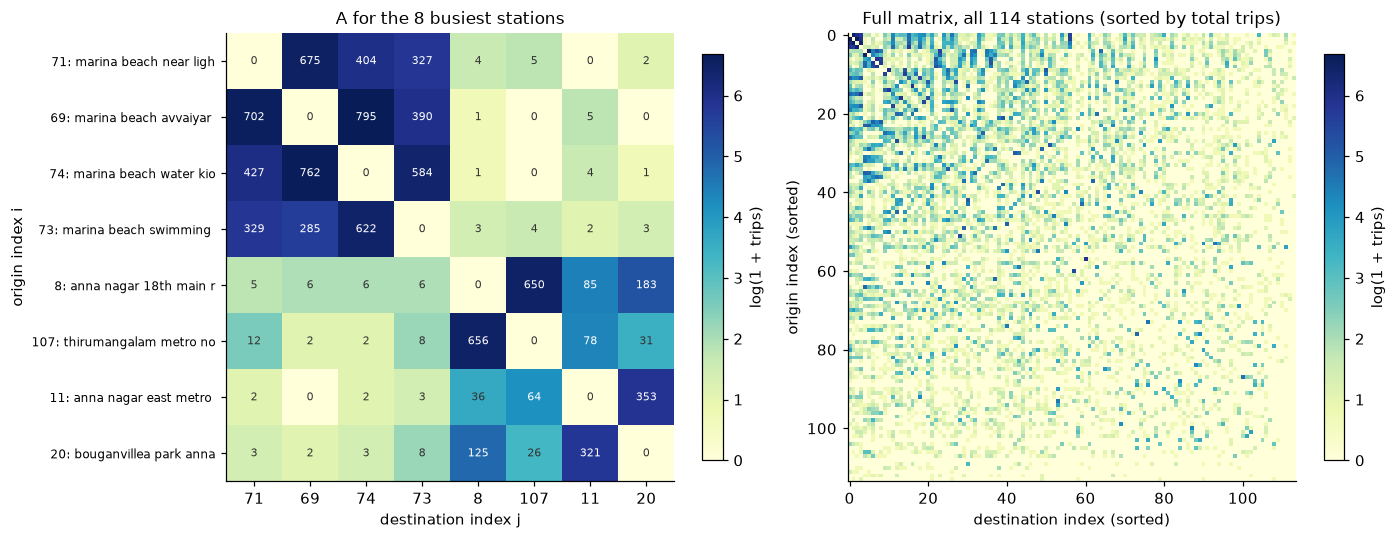

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))

im = ax[0].imshow(np.log1p(A[np.ix_(top8, top8)]), cmap="YlGnBu")
ax[0].set(xticks=range(8), yticks=range(8),
          title="A for the 8 busiest stations", xlabel="destination index j", ylabel="origin index i")
ax[0].set_xticklabels(top8); ax[0].set_yticklabels([f"{i}: {nodes[i][:22]}" for i in top8], fontsize=8)
ax[0].grid(False)
for p in range(8):
    for q in range(8):
        v = A[top8[p], top8[q]]
        ax[0].text(q, p, f"{v:.0f}", ha="center", va="center", fontsize=7.5,
                   color="white" if np.log1p(v) > np.log1p(A[np.ix_(top8, top8)]).max() * .6 else "#333")
plt.colorbar(im, ax=ax[0], shrink=.8, label="log(1 + trips)")

order = np.argsort(-(A.sum(1) + A.sum(0)))
im2 = ax[1].imshow(np.log1p(A[np.ix_(order, order)]), cmap="YlGnBu")
ax[1].set(title=f"Full matrix, all {N} stations (sorted by total trips)",
          xlabel="destination index (sorted)", ylabel="origin index (sorted)")
ax[1].grid(False)
plt.colorbar(im2, ax=ax[1], shrink=.8, label="log(1 + trips)")
plt.show()

## 5. Node table

In [15]:
node = index_tbl.copy()
st = pd.read_excel(f"{DATA}/bikesharing2.xlsx", sheet_name="109 live stations")
st.columns = [x.strip() for x in st.columns]
st = st.dropna(subset=["Station Name"]).copy()
st["o"] = st["Station Name"].map(key)
st.loc[st.Latitude > 90, "Latitude"] /= 1e6                    # one missing decimal point
st = st.drop_duplicates("o").set_index("o")

node["lat"]        = st.Latitude.reindex(nodes).values
node["lon"]        = st.Longitude.reindex(nodes).values
node["loops"]      = df[df.loop].groupby("o").size().reindex(nodes).fillna(0).astype(int).values
node["loop_share"] = (node.loops / node.out_trips.replace(0, np.nan)).round(3)
node["out_deg"]    = (A > 0).sum(1)                            # distinct destinations
node["in_deg"]     = (A > 0).sum(0)                            # distinct origins
node["deg"]        = ((A + A.T) > 0).sum(1)                    # distinct partners, either direction

print(f"{node.lat.notna().sum()} of {N} stations have surveyed coordinates")
node.sort_values("out_trips", ascending=False).head(8).to_string(index=False)

92 of 114 stations have surveyed coordinates


' idx                                         station  out_trips  in_trips       lat       lon  loops  loop_share  out_deg  in_deg  deg\n  69                    marina beach avvaiyar statue       9782      9238 13.046754 80.280711   6844       0.700       82      78   96\n  71                    marina beach near lighthouse       9081      8858       NaN       NaN   6247       0.688       84      84   97\n  74                        marina beach water kiosk       8498      8382 13.052079 80.281443   5805       0.683       80      84   95\n  67                                   mannady metro       6463      6482 13.095960 80.286342   5541       0.857       66      55   77\n  73                      marina beach swimming pool       6347      6470 13.058830 80.282760   4001       0.630       85      89   98\n   8                       anna nagar 18th main road       4819      4620 13.094920 80.200970   2756       0.572       72      54   79\n  20        bouganvillea park anna nagar east f

## 6. Graph properties

In [16]:
Au = ((A + A.T) > 0).astype(int); np.fill_diagonal(Au, 0)    # undirected, unweighted

def components(M):
    seen, comps = set(), []
    for s in range(len(M)):
        if s in seen: continue
        stack, comp = [s], []
        while stack:
            v = stack.pop()
            if v in seen: continue
            seen.add(v); comp.append(v); stack += list(np.where(M[v] > 0)[0])
        comps.append(comp)
    return comps

def eccentricity_bfs(M, src):
    dist = {src: 0}; frontier = [src]
    while frontier:
        nxt = []
        for v in frontier:
            for w in np.where(M[v] > 0)[0]:
                if w not in dist:
                    dist[w] = dist[v] + 1; nxt.append(w)
        frontier = nxt
    return max(dist.values()), np.mean(list(dist.values()))

comps = components(Au)
giant = max(comps, key=len)
ecc   = [eccentricity_bfs(Au, s) for s in giant]
tri   = np.trace(Au @ Au @ Au) / 6
triples = sum(d * (d - 1) / 2 for d in Au.sum(1))
B = (A > 0)

props = pd.Series({
    "nodes":                         N,
    "directed edges":                int(B.sum()),
    "undirected edges":              int(Au.sum() / 2),
    "possible directed pairs":       N * (N - 1),
    "density (directed)":            round(B.sum() / (N * (N - 1)), 4),
    "mean degree (partners)":        round(Au.sum(1).mean(), 1),
    "median degree":                 float(np.median(Au.sum(1))),
    "min degree":                    int(Au.sum(1).min()),
    "max degree":                    int(Au.sum(1).max()),
    "mean out-degree":               round(B.sum(1).mean(), 1),
    "mean in-degree":                round(B.sum(0).mean(), 1),
    "isolated nodes":                int((Au.sum(1) == 0).sum()),
    "connected components":          len(comps),
    "largest component":             len(giant),
    "diameter (hops)":               int(max(e[0] for e in ecc)),
    "mean shortest path (hops)":     round(float(np.mean([e[1] for e in ecc])), 2),
    "global clustering coefficient": round(3 * tri / triples, 3),
    "reciprocity (edges)":           round((B & B.T).sum() / B.sum(), 3),
    "mean trips per edge":           round(A[A > 0].mean(), 1),
    "median trips per edge":         float(np.median(A[A > 0])),
    "max trips on one edge":         int(A.max()),
    "edges with only 1 trip":        f"{(A == 1).sum()} ({(A == 1).sum() / (A > 0).sum():.0%})",
})
props.to_frame("value")

,value
nodes,114
directed edges,5731
undirected edges,3693
possible directed pairs,12882
density (directed),0.4449
mean degree (partners),64.8
median degree,69.0
min degree,15
max degree,107
mean out-degree,50.3


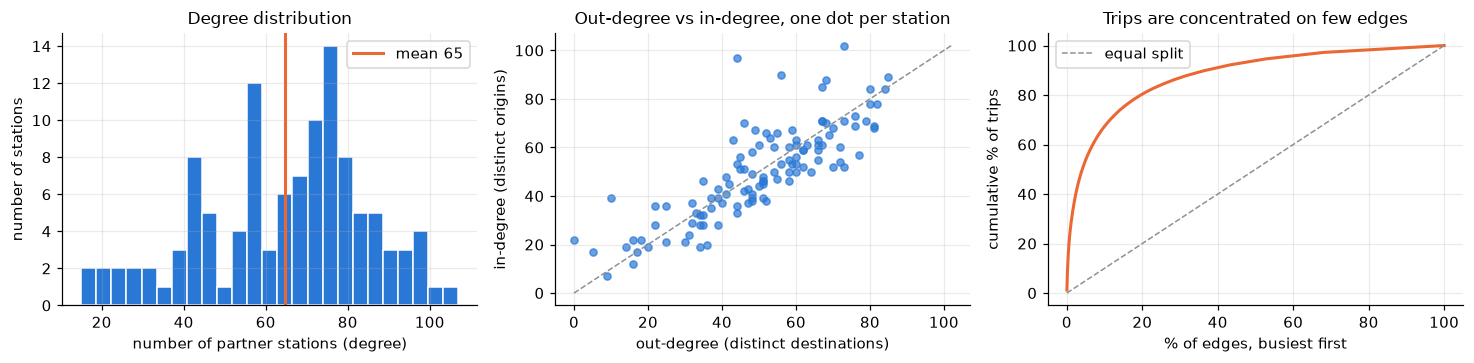

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.4))

ax[0].hist(Au.sum(1), bins=25, color=BLUE, edgecolor="white")
ax[0].axvline(Au.sum(1).mean(), color=ORANGE, lw=2, label=f"mean {Au.sum(1).mean():.0f}")
ax[0].set(xlabel="number of partner stations (degree)", ylabel="number of stations",
          title="Degree distribution"); ax[0].legend()

ax[1].scatter(B.sum(1), B.sum(0), s=22, color=BLUE, alpha=.7)
lim = max(B.sum(1).max(), B.sum(0).max())
ax[1].plot([0, lim], [0, lim], "--", color=GREY, lw=1)
ax[1].set(xlabel="out-degree (distinct destinations)", ylabel="in-degree (distinct origins)",
          title="Out-degree vs in-degree, one dot per station")

w = np.sort(A[A > 0])[::-1]
ax[2].plot(np.arange(1, len(w) + 1) / len(w) * 100, w.cumsum() / w.sum() * 100, color=ORANGE, lw=2)
ax[2].plot([0, 100], [0, 100], "--", color=GREY, lw=1, label="equal split")
ax[2].set(xlabel="% of edges, busiest first", ylabel="cumulative % of trips",
          title="Trips are concentrated on few edges"); ax[2].legend()
plt.show()

## 6b. The graph drawn on the map

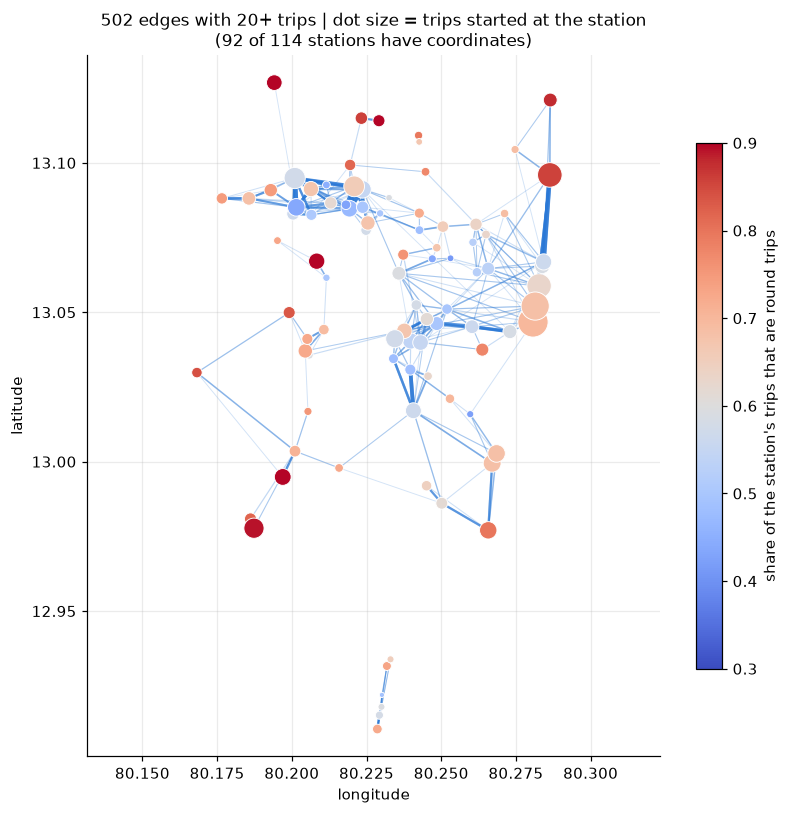

In [18]:
has_xy = node.lat.notna().values
strong = [(i, j) for i, j in zip(*np.where(A >= 20)) if has_xy[i] and has_xy[j]]

fig, ax = plt.subplots(figsize=(7.5, 7.5))
for i, j in strong:
    ax.plot([node.lon[i], node.lon[j]], [node.lat[i], node.lat[j]],
            color=BLUE, alpha=min(.75, .12 + A[i, j] / 250), lw=min(3, .4 + A[i, j] / 100), zorder=1)
sc = ax.scatter(node.lon[has_xy], node.lat[has_xy], s=node.out_trips[has_xy] / 25,
                c=node.loop_share[has_xy], cmap="coolwarm", vmin=.3, vmax=.9,
                edgecolor="white", linewidth=.6, zorder=3)
plt.colorbar(sc, ax=ax, shrink=.75, label="share of the station's trips that are round trips")
ax.set(xlabel="longitude", ylabel="latitude",
       title=f"{len(strong)} edges with 20+ trips | dot size = trips started at the station\n"
             f"({int(has_xy.sum())} of {N} stations have coordinates)")
ax.set_aspect("equal", adjustable="datalim")
plt.show()

## 7. Quick EDA on the trips behind the graph

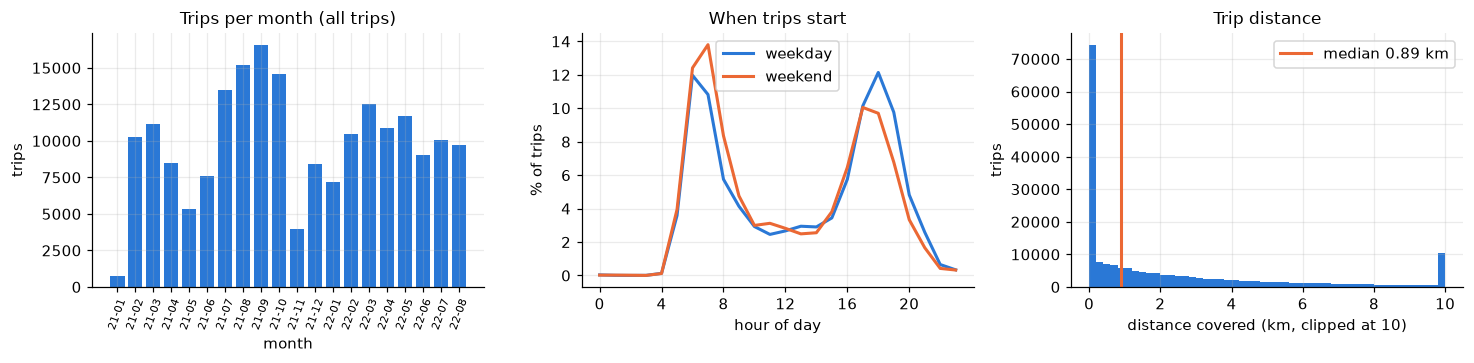

            distance_covered  ride_time
loop                                   
one way                 2.79       25.0
round trip              0.08       10.0


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.4))

mth = df.groupby("month").size()
ax[0].bar([str(m)[2:] for m in mth.index], mth.values, color=BLUE)
ax[0].set(ylabel="trips", xlabel="month", title="Trips per month (all trips)")
ax[0].tick_params(axis="x", rotation=70, labelsize=7)

hr = df.hour if "hour" in df else df.t.dt.hour
for lab, mask, col in [("weekday", df.t.dt.dayofweek < 5, BLUE), ("weekend", df.t.dt.dayofweek >= 5, ORANGE)]:
    s = hr[mask].value_counts(normalize=True).sort_index() * 100
    ax[1].plot(s.index, s.values, lw=2, color=col, label=lab)
ax[1].set(xlabel="hour of day", ylabel="% of trips", title="When trips start", xticks=range(0, 24, 4))
ax[1].legend()

ax[2].hist(df.distance_covered.clip(0, 10), bins=50, color=BLUE)
ax[2].axvline(df.distance_covered.median(), color=ORANGE, lw=2,
              label=f"median {df.distance_covered.median():.2f} km")
ax[2].set(xlabel="distance covered (km, clipped at 10)", ylabel="trips",
          title="Trip distance"); ax[2].legend()
plt.show()

print(df.groupby("loop")[["distance_covered", "ride_time"]].median()
        .rename(index={True: "round trip", False: "one way"}).round(2).to_string())

## 8. Q1 — how many stations are active each month?

In [20]:
active = {m: set(df[df.month == m].o) | set(df[df.month == m].d) for m in months}

seen, rows = set(), []
for i, m in enumerate(months):
    a = active[m]
    new   = a - seen                                     # never active in any earlier month
    back  = (a & seen) - active[months[i-1]] if i else set()   # active before, idle last month, back now
    gone  = active[months[i-1]] - a if i else set()
    rows.append({"month": str(m), "active_stations": len(a), "new_stations": len(new),
                 "returning": len(back), "went_idle": len(gone)})
    seen |= a
nodes_m = pd.DataFrame(rows)
print(nodes_m.to_string(index=False))

  month  active_stations  new_stations  returning  went_idle
2021-01               49            49          0          0
2021-02               88            39          0          0
2021-03               88             0          0          0
2021-04               89             1          0          0
2021-05               85             0          0          4
2021-06               87             0          3          1
2021-07               94             6          2          1
2021-08               99             6          0          1
2021-09              109             8          2          0
2021-10              109             0          0          0
2021-11              105             0          0          4
2021-12              112             3          4          0
2022-01              110             0          0          2
2022-02              109             0          0          1
2022-03              111             1          1          0
2022-04              112

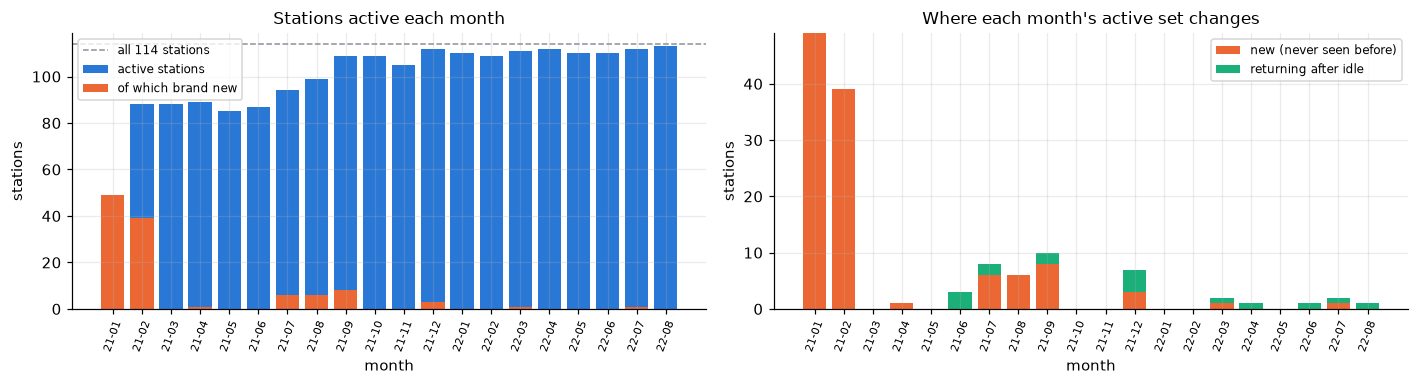

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
x = range(len(months)); lab = [str(m)[2:] for m in months]

ax[0].bar(x, nodes_m.active_stations, color=BLUE, label="active stations")
ax[0].bar(x, nodes_m.new_stations, color=ORANGE, label="of which brand new")
ax[0].axhline(N, color=GREY, ls="--", lw=1, label=f"all {N} stations")
ax[0].set(xticks=list(x), ylabel="stations", xlabel="month",
          title="Stations active each month")
ax[0].set_xticklabels(lab, rotation=70, fontsize=7); ax[0].legend(fontsize=8)

ax[1].bar(x, nodes_m.new_stations, color=ORANGE, label="new (never seen before)")
ax[1].bar(x, nodes_m.returning, bottom=nodes_m.new_stations, color=GREEN, label="returning after idle")
ax[1].set(xticks=list(x), ylabel="stations", xlabel="month",
          title="Where each month's active set changes")
ax[1].set_xticklabels(lab, rotation=70, fontsize=7); ax[1].legend(fontsize=8)
plt.show()

## Q2 — are the active station pairs sparse each month?

In [23]:
rows = []
for t, m in enumerate(months):
    e  = int((S[t] > 0).sum())
    na = len(active[m])
    prev = (S[t-1] > 0) if t else None
    cur  = (S[t] > 0)
    rows.append({"month": str(m),
                 "trips": int(S[t].sum()),
                 "active_pairs": e,
                 "pct_of_all_pairs": round(100 * e / (N * (N - 1)), 1),
                 "pct_of_active_pairs": round(100 * e / max(1, na * (na - 1)), 1),
                 "jaccard_vs_prev": round(float((cur & prev).sum() / (cur | prev).sum()), 2) if t else np.nan,
                 "new_pairs_pct": round(100 * float((cur & ~(S[:t] > 0).any(0)).sum() / e), 1) if t else np.nan})
pairs_m = pd.DataFrame(rows)
print(pairs_m.to_string(index=False))
print(f"\nmean: {pairs_m.active_pairs.mean():.0f} active pairs per month, "
      f"{pairs_m.pct_of_all_pairs.mean():.1f}% of all {N*(N-1):,} pairs, "
      f"{pairs_m.pct_of_active_pairs.mean():.1f}% of pairs between active stations")
print(f"cumulative: {int((S.sum(0) > 0).sum()):,} pairs ever used "
      f"({100*(S.sum(0) > 0).sum()/(N*(N-1)):.1f}% of all pairs)")

  month  trips  active_pairs  pct_of_all_pairs  pct_of_active_pairs  jaccard_vs_prev  new_pairs_pct
2021-01    271           143               1.1                  6.1              NaN            NaN
2021-02   2907           906               7.0                 11.8             0.11           88.1
2021-03   3457           911               7.1                 11.9             0.35           47.0
2021-04   2431           804               6.2                 10.3             0.35           33.1
2021-05   1597           641               5.0                  9.0             0.28           34.8
2021-06   2364           743               5.8                  9.9             0.26           28.4
2021-07   3952          1079               8.4                 12.3             0.30           31.8
2021-08   4254          1239               9.6                 12.8             0.31           36.5
2021-09   5286          1541              12.0                 13.1             0.31           34.8
